In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder

In [2]:
df = pd.read_csv("smartphones.csv")

In [3]:
print(df.head())
print(df.info())
print(df.describe())

  brand_name                      model  price  rating  has_5g  has_nfc  \
0    oneplus              OnePlus 11 5G  54999    89.0    True     True   
1    oneplus  OnePlus Nord CE 2 Lite 5G  19989    81.0    True    False   
2    samsung      Samsung Galaxy A14 5G  16499    75.0    True    False   
3   motorola       Motorola Moto G62 5G  14999    81.0    True    False   
4     realme         Realme 10 Pro Plus  24999    82.0    True    False   

   has_ir_blaster processor_brand  num_cores  processor_speed  ...  \
0           False      snapdragon        8.0              3.2  ...   
1           False      snapdragon        8.0              2.2  ...   
2           False          exynos        8.0              2.4  ...   
3           False      snapdragon        8.0              2.2  ...   
4           False       dimensity        8.0              2.6  ...   

   refresh_rate  num_rear_cameras  num_front_cameras       os  \
0           120                 3                1.0  android  

In [4]:
df.replace("", np.nan, inplace=True)
df.dropna(subset=['price'], inplace=True)

In [5]:
bool_cols = ['has_5g', 'has_nfc', 'has_ir_blaster', 'fast_charging_available', 'extended_memory_available']
df[bool_cols] = df[bool_cols].astype('bool')

In [6]:
numeric_cols = ['rating', 'fast_charging', 'ram_capacity', 'internal_memory',
                'refresh_rate', 'num_rear_cameras', 'num_front_cameras',
                'primary_camera_rear', 'primary_camera_front',
                'extended_upto', 'resolution_width', 'resolution_height']

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')


In [7]:
df.dropna(inplace=True)

In [8]:
le = LabelEncoder()
cat_cols = ['brand_name', 'model', 'processor_brand', 'os']
for col in cat_cols:
    df[col] = le.fit_transform(df[col])

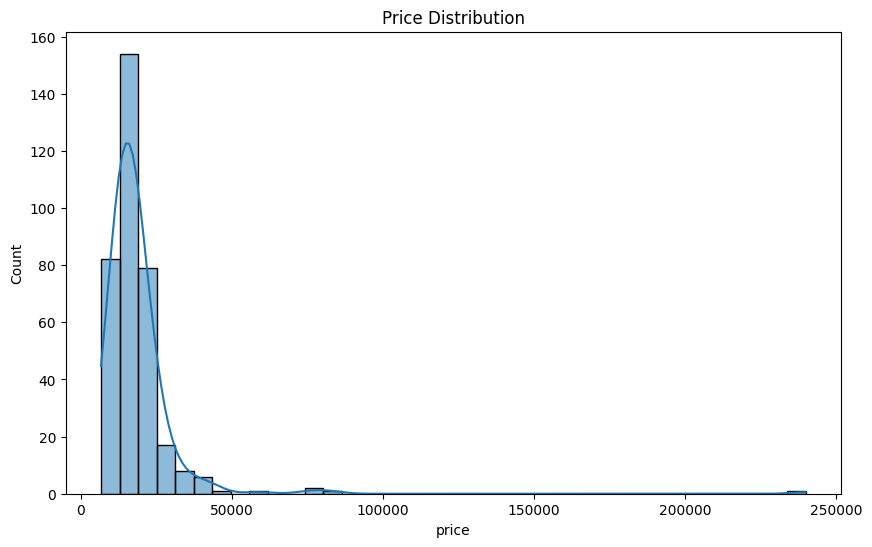

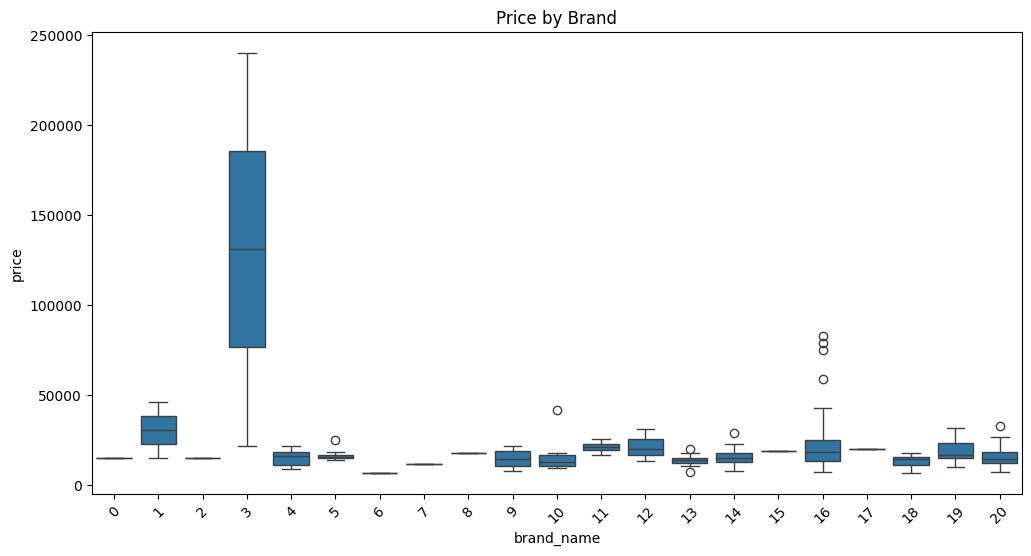

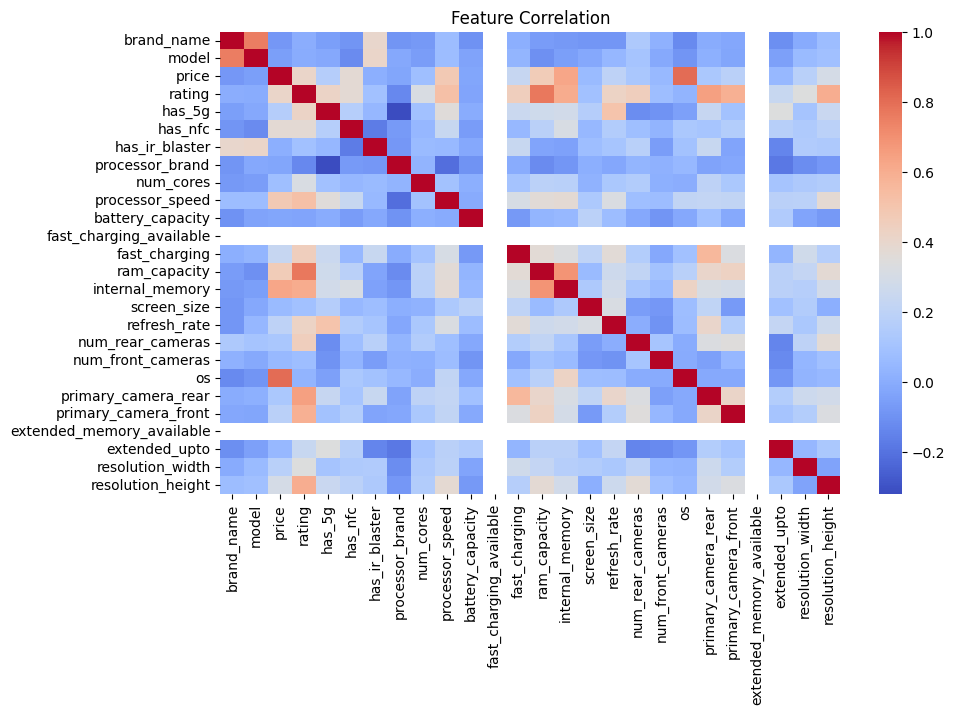

In [9]:
plt.figure(figsize=(10,6))
sns.histplot(df['price'], kde=True)
plt.title("Price Distribution")
plt.show()

plt.figure(figsize=(12,6))
sns.boxplot(x='brand_name', y='price', data=df)
plt.xticks(rotation=45)
plt.title("Price by Brand")
plt.show()

plt.figure(figsize=(10,6))
sns.heatmap(df.corr(), annot=False, cmap='coolwarm')
plt.title("Feature Correlation")
plt.show()

In [10]:
X = df.drop(['price', 'model'], axis=1)  # Drop 'model' for generalization
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)


,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [11]:
y_pred = model.predict(X_test)

print("🔢 R2 Score:", r2_score(y_test, y_pred))
print("📉 RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

🔢 R2 Score: 0.775468400669466
📉 RMSE: 2899.957509110731


In [12]:
sample = X.iloc[0:1]
predicted_price = model.predict(sample)
print(f"📱 Predicted Price for sample phone: ₹{predicted_price[0]:,.0f}")

📱 Predicted Price for sample phone: ₹19,953
